# Share one object with ray.put

A Put node stores a value in the object store once; two tasks receive the same ObjectRef instead of each getting their own copy.

**When to use it.** Large inputs (a lookup table, model weights, a DataFrame) that many tasks read.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

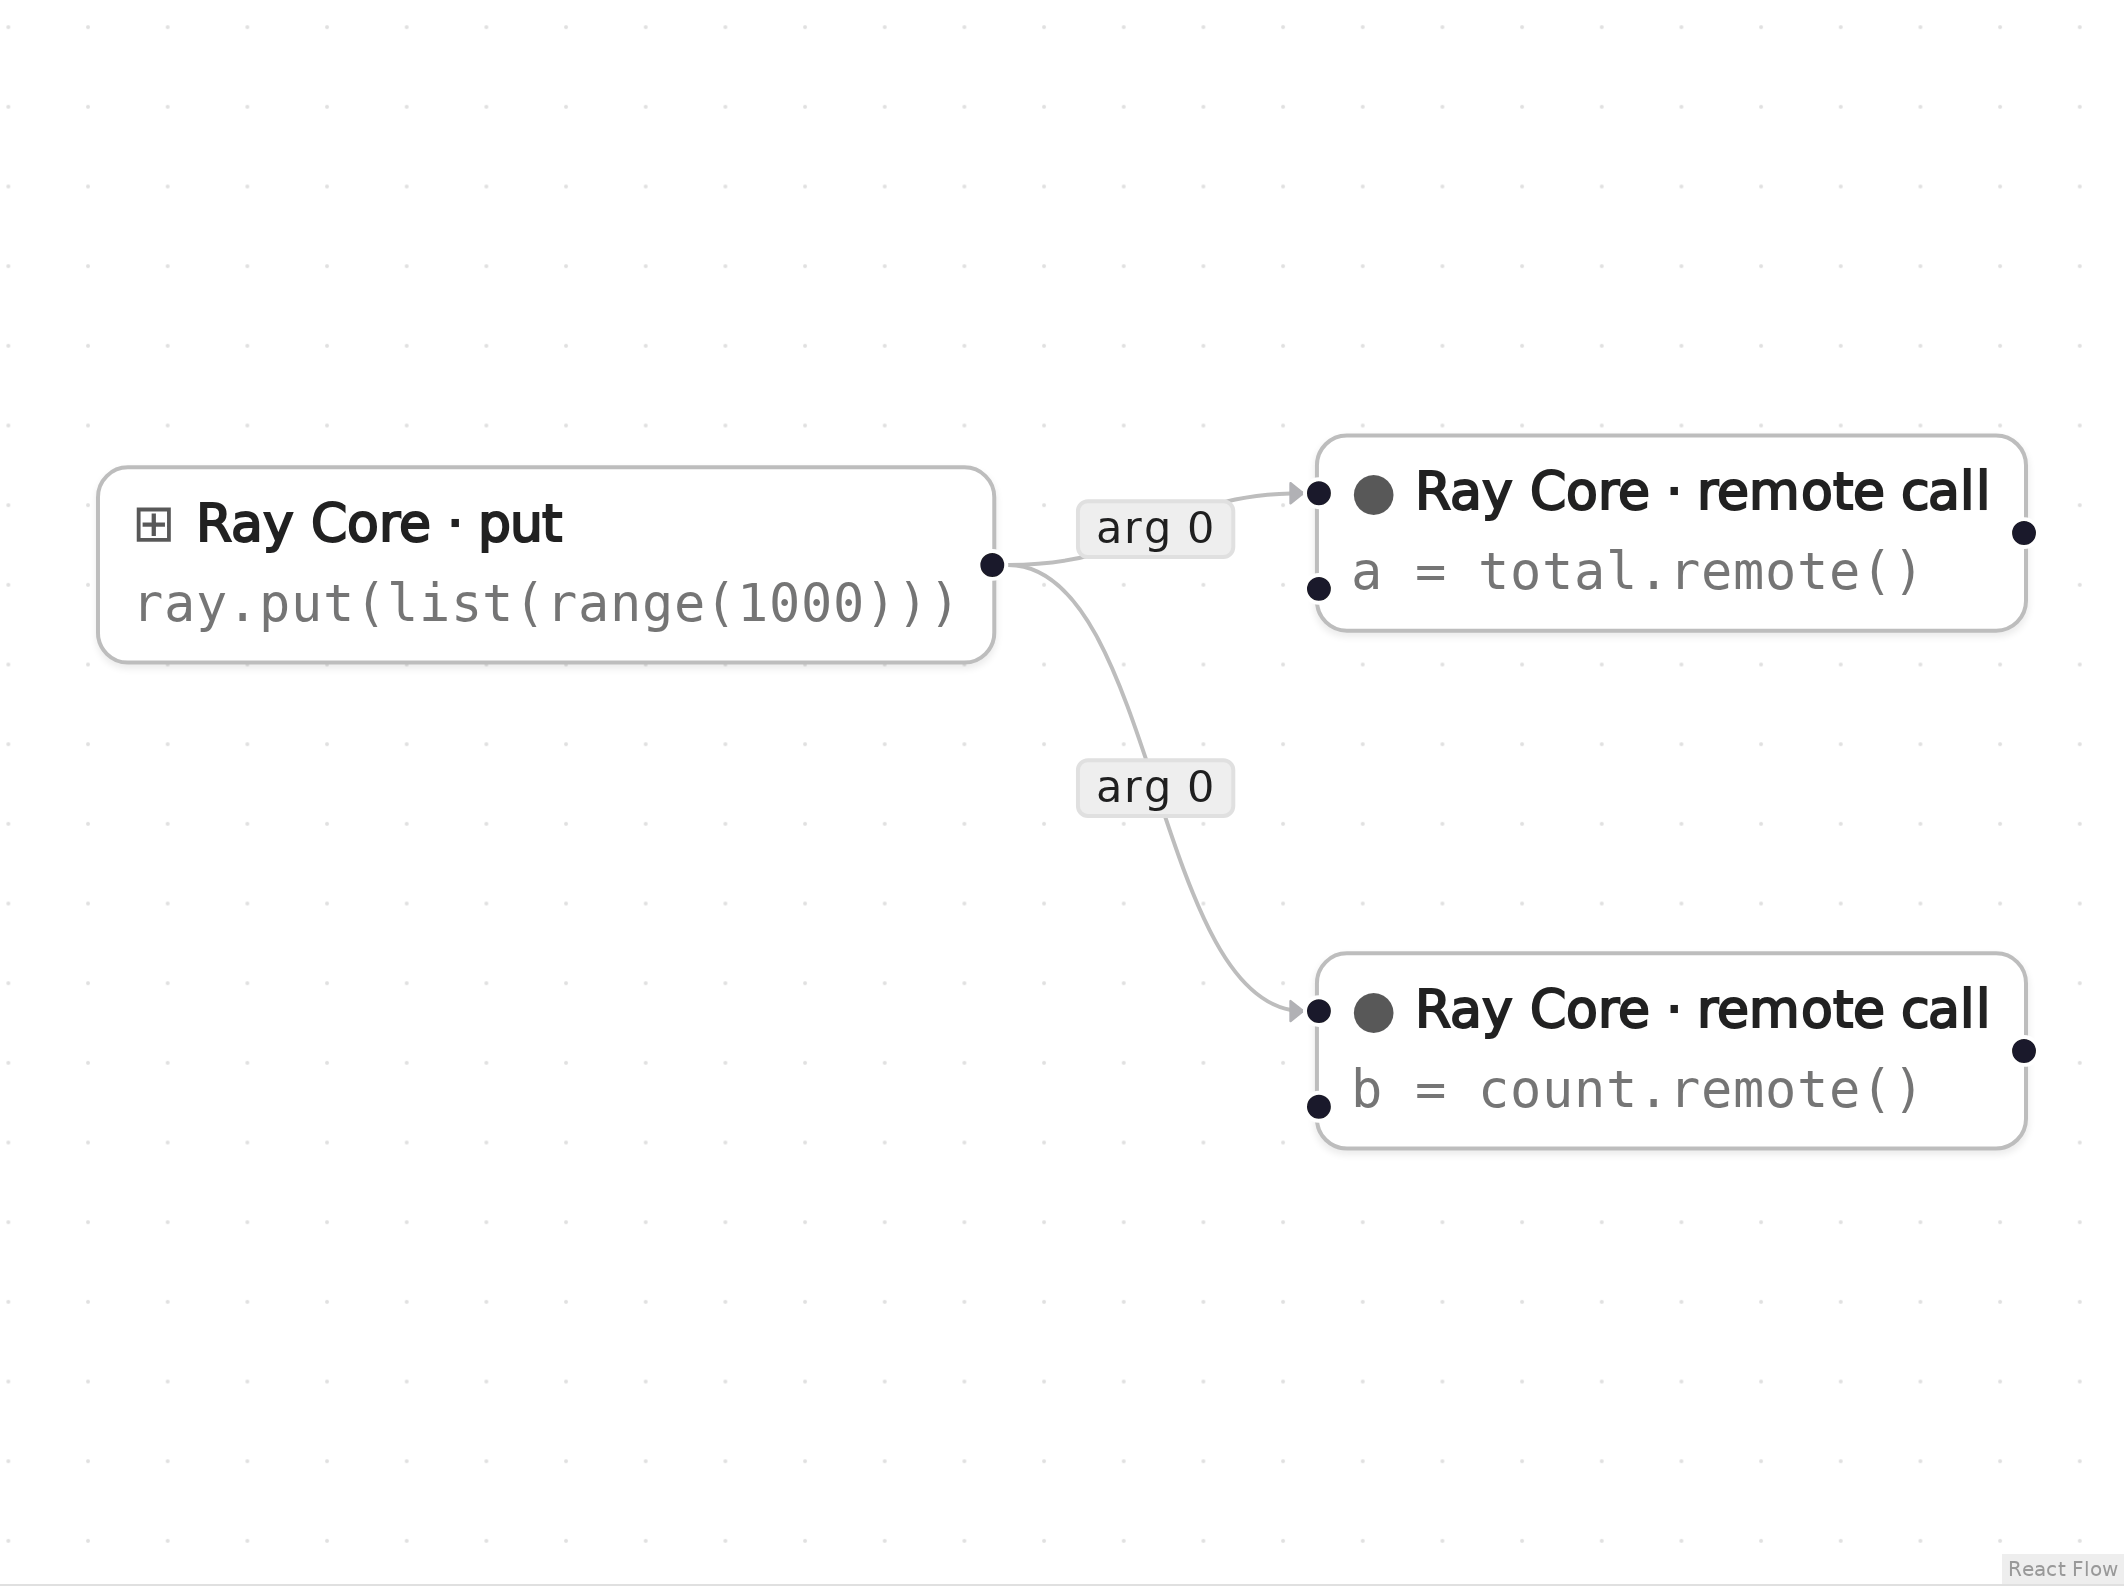

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
def total(values):
    return sum(values)


def count(values):
    return len(values)

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

import ray

if not ray.is_initialized():
    ray.init()

data_ref = ray.put(list(range(1000)))
_n1 = ray.remote(total).remote(data_ref)
a = ray.get(_n1)
_n2 = ray.remote(count).remote(data_ref)
b = ray.get(_n2)

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
assert a == 499500, a
assert b == 1000, b
print("total =", a, "count =", b)

total = 499500 count = 1000


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3 and 5–6)

```python
# Generated with Eugo's visual Ray builder
...
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Put** (node `p1`, line 8)

```python
data_ref = ray.put(list(range(1000)))
```

ray.put serializes the list into the shared object store once and returns an ObjectRef.

**Remote task** (node `n1`, lines 9–10)

```python
_n1 = ray.remote(total).remote(data_ref)
a = ray.get(_n1)
```

Receives the ref as an argument; Ray hands the task the stored value.

**Remote task** (node `n2`, lines 11–12)

```python
_n2 = ray.remote(count).remote(data_ref)
b = ray.get(_n2)
```

A second task reads the same stored object without another copy from the driver.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()